# Sensibilidad directa e identificabilidad

**Pregunta:** ¿Qué diferencias entre optimizadores sobreviven a una comparación con datos idénticos?

**Nivel 3 — Crítica de investigación**  
**Prerrequisitos:** niveles 1–2 y fundamentos de inversión; 35 min.



## Objetivos

Pregunta: ¿Qué ventanas de frecuencia resuelven localmente el modelo de espesores fijos y Adam alcanza la solución sintética de la ruta trust-region?



## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8` `scipy==1.15.2` es requerido por el operador directo MT.



## Datos

El experimento de optimizadores usa 60 frecuencias entre 0.001–100 Hz, espesores fijos de 300 m y 700 m, verdad de tres capas de 80/12/250 Ω·m y una máscara congelada. Un control separado de 24 frecuencias prueba rango local por banda. Clear Lake cl061 queda fuera de ambos ajustes porque falla su filtro 1D medido.


## Método

El operador estratificado del repositorio usa respuesta de semiespacio `Z=√(iωμ₀ρ)` y la propaga recursivamente por capas finitas usando `k=√(iωμ₀/ρ)`, `w=√(iωμ₀ρ)` y `t=tanh(kh)`. La base es infinita; la geometría es 1D, isótropa y cuasiestática. Use las funciones existentes `electromagnetics.impedance` y `curves`, sin reimplementarlas. Compare la verdad sintética exacta con un ajuste guardado sobre las frecuencias versionadas, graficando resistividad aparente (Ω·m) y fase (grados) frente al período (s). Curvas parecidas no prueban unicidad de resistividad o espesor: dimensionalidad, static shift, errores correlacionados y espesor fijo quedan fuera de la calibración.

Los parámetros son log-resistividades: el logaritmo de resistividad impone positividad y hace que la regularización penalice contrastes relativos. Residuos complejos usan sigma por componente real; ambas partes aportan al ajuste. Frecuencias no son muestras independientes de profundidad: las columnas del Jacobiano se solapan entre bandas; ningún período aislado identifica una interfaz. Sensibilidad local y cobertura dependen de parametrización fija y no descartan equivalencia global.



## Comparación

La comparación distingue los métodos publicados, el código del producto y la evidencia versionada. Una afirmación de avance requiere dominios retenidos independientes, incertidumbre calibrada y réplica.



In [1]:
from pathlib import Path
from importlib.metadata import version

print("Versiones del entorno:", {name: version(name) for name in ["numpy", "matplotlib", "scipy"]})
import numpy as np

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
# Llame al operador directo de tierra estratificada del repositorio para su objetivo de calibración sintético.
import json, sys
from pathlib import Path

sys.path.insert(0, str(root / "data-pipeline"))
import electromagnetics as em
from electromagnetics import impedance, curves

cal = json.loads((root / "data/derived/v2/edi/calibration-two-layer.json").read_text(encoding="utf-8"))
f = cal["frequencies_hz"]
rho = cal["calibration_model"]
h = cal["fixed_thickness_m"]
z = impedance(rho, h, f)
truth = curves(z, f)
print("rho sintética Ω·m", rho, "espesor fijo (m)", h, "número de frecuencias", len(f))


Versiones del entorno: {'numpy': '2.2.6', 'matplotlib': '3.10.8', 'scipy': '1.15.2'}
rho sintética Ω·m [180.0, 20.0] espesor fijo (m) [450.0] número de frecuencias 24


### Intercambio de conductancia con espesor fijo

Espesor y resistividad cambian juntos; el residual de impedancia blanqueado mide cómo estas frecuencias distinguen la perturbación.

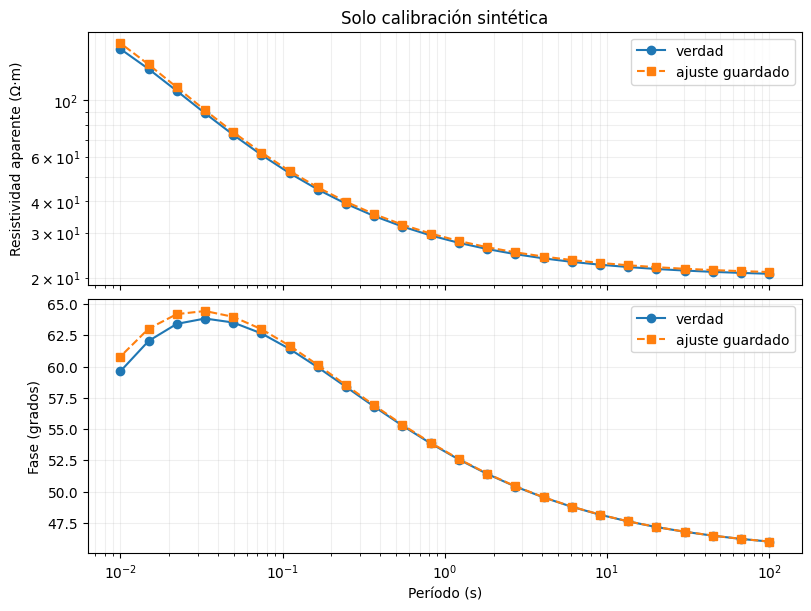

rho ajustada guardada Ω·m [198.92475596650235, 20.323660137129647]


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Proyecte hacia adelante un modelo ajustado guardado y compare las curvas de respuesta física.
import matplotlib.pyplot as plt

fit = cal["rows"][0]['model']
other = curves(impedance(fit, h, f), f)
T = 1 / np.asarray(f)
fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True, constrained_layout=True)
ax[0].loglog(T, truth["apparent"], "o-", label="verdad")
ax[0].loglog(T, other["apparent"], "s--", label="ajuste guardado")
ax[1].semilogx(T, truth["phase"], "o-", label="verdad")
ax[1].semilogx(T, other["phase"], "s--", label="ajuste guardado")
ax[0].set_ylabel("Resistividad aparente (Ω·m)")
ax[1].set_ylabel("Fase (grados)")
ax[1].set_xlabel("Período (s)")
[a.grid(True, which="both", alpha=0.2) or a.legend() for a in ax]
ax[0].set_title("Solo calibración sintética")
plt.show()
print("rho ajustada guardada Ω·m", fit)


### Experimento sintético: cobertura de frecuencias, ruido y equivalencia de espesor

Este experimento directo adicional **sintético** se separa del registro medido `cl061`. El operador estratificado del repositorio genera una respuesta exacta de tres capas. Su rutina implementada `identifiability` linealiza respecto de log-resistividad con ambos espesores fijos. Compare la banda completa con subconjuntos solo de bajas y altas frecuencias usando el mismo modelo y la misma incertidumbre por componente. Los valores singulares y la SD local de log-resistividad son diagnósticos condicionales de sensibilidad, no incertidumbre posterior ni prueba de unicidad.

Una segunda perturbación directa aumenta conjuntamente el espesor y la resistividad de la capa conductora finita, preservando aproximadamente su conductancia (`h/ρ`). Compare el cambio de respuesta compleja con la escala de ruido declarada. Esta equivalencia conocida es aproximada para una respuesta estratificada de frecuencia finita. Muestra el supuesto de espesor fijo; no es una segunda inversión, una afirmación de geología recuperada ni evidencia sobre `cl061`.

In [3]:
# Experimento solo sintético: sensibilidad local con espesor fijo y ventanas de frecuencia.
f_syn = np.logspace(-3, 2, 60)
active_syn = np.arange(len(f_syn)) % 4 != 1
h_syn = np.array([300.0, 700.0])
rho_syn = np.array([80.0, 12.0, 250.0])
z_syn = impedance(rho_syn, h_syn, f_syn)
sigma_syn = np.maximum(0.03 * np.abs(z_syn), 1e-12)  # SD de cada componente real e imaginaria independiente
bands = {
    "banda completa 0.001–100 Hz": np.ones(len(f_syn), dtype=bool),
    "baja frecuencia ≤0.1 Hz": f_syn <= 0.1,
    "alta frecuencia ≥1 Hz": f_syn >= 1.0,
}


### Evaluar sensibilidad por ventana de frecuencia

La identificabilidad usa un modelo de espesores fijos y sus incertidumbres por componente. El barrido contrasta rango local y sensibilidad paramétrica en subconjuntos completo, bajo y alto.

In [4]:
# Calcula rango local y sensibilidad para cada máscara de frecuencia.
diags = {}
for label, mask in bands.items():
    d = em.identifiability(rho_syn, h_syn, f_syn, sigma_syn, mask)
    diags[label] = d
    print(
        label,
        "N=",
        int(mask.sum()),
        "rango efectivo=",
        d["effective_rank"],
        "/",
        d["parameter_count"],
        "valores singulares=",
        np.round(d["singular_values"], 3),
        "SD local de log-rho=",
        np.round(d["local_logrho_sd"], 3),
        "capas no resueltas=",
        d["unresolved_layers"],
        "estado=",
        d["status"],
    )


banda completa 0.001–100 Hz N= 60 rango efectivo= 3 / 3 valores singulares= [107.981  61.827  27.976] SD local de log-rho= [0.036 0.011 0.015] capas no resueltas= [] estado= locally_resolved
baja frecuencia ≤0.1 Hz N= 24 rango efectivo= 2 / 3 valores singulares= [71.098 31.793  0.1  ] SD local de log-rho= [9.974 0.668 0.022] capas no resueltas= [0] estado= unresolved
alta frecuencia ≥1 Hz N= 24 rango efectivo= 3 / 3 valores singulares= [64.944 27.966  6.79 ] SD local de log-rho= [0.036 0.017 0.147] capas no resueltas= [] estado= locally_resolved


### Probar el intercambio de conductancia de capa finita

El barrido de sensibilidad informa el rango del Jacobiano y la incertidumbre local para cada ventana de frecuencia. Este cálculo directo separado perturba conjuntamente el espesor y la resistividad de la capa finita, y mide la discrepancia de impedancia blanqueada por ruido.

In [5]:
# Perturbación directa h/rho de la capa conductora finita.
rho_trade = np.array([rho_syn[0], rho_syn[1] * 1.15, rho_syn[2]])
h_trade = np.array([h_syn[0], h_syn[1] * 1.15])
z_trade = impedance(rho_trade, h_trade, f_syn)
whitened = np.abs(z_trade - z_syn) / sigma_syn
trade_wrms = float(np.sqrt(np.mean(whitened**2) / 2))
print("Equivalencia sintética de conductancia; h base m=", h_syn, "rho ohm m=", rho_syn)
print("h perturbado m=", h_trade, "rho ohm m=", rho_trade, "; WRMS por componente blanqueado=", trade_wrms)


Equivalencia sintética de conductancia; h base m= [300. 700.] rho ohm m= [ 80.  12. 250.]
h perturbado m= [300. 805.] rho ohm m= [ 80.   13.8 250. ] ; WRMS por componente blanqueado= 0.5429574698818997


Ejecute región de confianza acotada sobre respuesta sintética recién calculada.

In [6]:
# Ejecute región de confianza acotada sobre respuesta sintética recién calculada.
active_syn = np.arange(len(f_syn)) % 4 != 1
fit_lm = em.invert_mt(
    h_syn, f_syn, z_syn, sigma_syn, active=active_syn, initial=rho_syn * 1.2, methods=("mt-lm",), max_nfev=120
)["mt-lm"]
print("Modelo LM Ω·m:", np.round(fit_lm['model'], 3), "WRMS:", fit_lm["metrics"]["active_component_wrms"])


Modelo LM Ω·m: [ 79.987  12.001 249.984] WRMS: 0.0006162534002809828


Ejecute el método CPU alternativo con los mismos datos y modelo inicial.

In [7]:
import os
# Ejecute el optimizador del producto basado en Torch en el entorno aislado del pipeline.
import json, os, subprocess
from pathlib import Path

work = Path(os.environ["CAOS_TEMP_ROOT"]) / "caos-geophysics-mt-notebook"
work.mkdir(parents=True, exist_ok=True)
input_path = work / "mt-adam-input.json"
output_path = work / "mt-adam-output.json"
request = {
    "h": h_syn.tolist(),
    "f": f_syn.tolist(),
    "rho": rho_syn.tolist(),
    "sigma": sigma_syn.tolist(),
    "active": active_syn.tolist(),
    "z_real": z_syn.real.tolist(),
    "z_imag": z_syn.imag.tolist(),
    "initial": (rho_syn * 1.2).tolist(),
}
input_path.write_text(json.dumps(request), encoding="utf-8")
engine_root = Path(os.environ.get("CAOS_SOURCE_ROOT", root))
engine = engine_root / ".venv-pipeline" / "Scripts" / "python.exe"
if not engine.is_file():
    raise RuntimeError("The isolated pipeline environment is required for Torch-backed mt-adam.")


### Preparar la solicitud del optimizador aislado

La solicitud se escribe bajo la raíz temporal configurada y se comprueba el intérprete dedicado del pipeline antes de ensamblar el proceso hijo. No se sustituye el método Torch por una aproximación local del notebook.

In [8]:
# Preparar la solicitud del optimizador aislado.
child = "\n".join(
    [
        "import json, sys",
        "from pathlib import Path",
        "import numpy as np",
        "sys.path.insert(0, str(Path(sys.argv[1]) / 'data-pipeline'))",
        "import electromagnetics as em",
        "source = json.loads(Path(sys.argv[2]).read_text(encoding='utf-8'))",
        "z = np.asarray(source['z_real']) + 1j * np.asarray(source['z_imag'])",
        "fit = em.invert_mt(",
    "    source['h'], source['f'], z, source['sigma'],",
    "    active=source['active'], initial=source['initial'],",
    "    methods=('mt-adam',), adam_steps=1200,",
    ")['mt-adam']",
        "answer = {",
    "    'model': np.asarray(fit['model']).tolist(),",
    "    'active_wrms': float(fit['metrics']['active_component_wrms']),",
    "    'heldout_wrms': float(fit['metrics']['withheld_component_wrms']),",
    "}",
        "Path(sys.argv[3]).write_text(json.dumps(answer), encoding='utf-8')",
    ]
)


### Ejecutar el método Adam del producto

Este programa hijo importa la implementación del repositorio en el entorno aislado, llama `invert_mt` con `mt-adam` y serializa el modelo recuperado junto con métricas activas y reservadas para este kernel.

In [9]:
# Ejecutar el método Adam del producto.
completed = subprocess.run(
    [str(engine), "-c", child, str(root), str(input_path), str(output_path)],
    cwd=root,
    capture_output=True,
    text=True,
    timeout=300,
)
if completed.returncode:
    raise RuntimeError(completed.stderr[-3000:])
adam_result = json.loads(output_path.read_text(encoding="utf-8"))
print(
    "Modelo Adam Ω·m:",
    np.round(adam_result['model'], 3),
    "WRMS de ajuste:",
    adam_result["active_wrms"],
    "WRMS retenido:",
    adam_result["heldout_wrms"],
)


Modelo Adam Ω·m: [ 79.987  12.001 249.984] WRMS de ajuste: 0.0006162534252895064 WRMS retenido: 0.0005956383478404238


### Inversion con motor directo independiente: SimPEG 1D NSEM

Esta referencia construye un Simulation1DRecursive de SimPEG con receptores de impedancia real e imaginaria para cada frecuencia sintetica. SimPEG ordena las capas desde la base hacia la superficie y usa el signo opuesto de impedancia con su convencion declarada de coordenadas y Fourier. El adaptador invierte el orden de capas y espesores y cambia el signo de Z; luego comprueba la respuesta compleja frente al operador directo del producto antes del ajuste. La discrepancia relativa maxima debe ser menor que 1e-7. La inversion usa minimos cuadrados acotados de region de confianza de SciPy sobre la respuesta SimPEG, con la misma mascara activa, sigma por componente real, cotas logaritmicas, modelo inicial, beta=0.001 y penalizacion de suavidad entre log-resistividades adyacentes del objetivo del producto. Asi se evalua un motor fisico y un adaptador de convenciones implementados de forma independiente, no un algoritmo de optimizacion independiente. Las frecuencias retenidas se excluyen del ajuste y se puntuan despues. Es un control de software sintetico; no valida un modelo de campo ni demuestra novedad.


In [10]:
# Independent physical forward engine: SimPEG 0.25.2 recursive 1D NSEM.
# SimPEG orders layers from the half-space upward and uses the opposite impedance sign here.
# Reverse the product's top-down model and thicknesses, then convert Z_simpeg -> -Z_product.
from scipy.optimize import least_squares
from simpeg import maps
from simpeg.electromagnetics import natural_source as nsem

simpeg_sources = []
for frequency in f_syn:
    receivers = [
        nsem.receivers.Impedance([[0.0, 0.0, 0.0]], orientation="xy", component=component)
        for component in ("real", "imag")
    ]
    simpeg_sources.append(nsem.sources.Planewave(receivers, frequency=float(frequency)))
simpeg_survey = nsem.Survey(simpeg_sources)
simpeg_simulation = nsem.Simulation1DRecursive(
    survey=simpeg_survey,
    sigmaMap=maps.ExpMap(nP=len(rho_syn)),
    thicknesses=h_syn[::-1].copy(),
)

def simpeg_impedance(logrho_top_down):
    # ExpMap consumes log conductivity, ordered bottom-up by SimPEG.
    values = simpeg_simulation.dpred(-np.asarray(logrho_top_down)[::-1])
    return -(values[::2] + 1j * values[1::2])

# First verify the two forward engines at the declared synthetic truth.
simpeg_truth = simpeg_impedance(np.log(rho_syn))
forward_relative_error = float(np.max(np.abs(simpeg_truth - z_syn) / np.maximum(np.abs(z_syn), 1e-30)))
assert forward_relative_error < 1e-7, f"SimPEG convention/order parity failed: {forward_relative_error:g}"


### Ajustar el mismo objetivo declarado con el operador directo independiente

Tras verificar que los signos y el orden de capas coinciden en la verdad sintética, resolvemos con SimPEG el mismo residual activo y la misma escala de suavidad adyacente en log-resistividad. Los períodos retenidos no participan en el ajuste; se informan por separado. Este control contrasta una ruta de operador directo independiente, no datos de terreno ni rendimiento universal.


In [11]:
# Match the same active-frequency objective and smoothness scaling in the reference solve.
# Match the product objective exactly: active complex residuals are scaled per real component,
# and the adjacent log-resistivity smoothness penalty has the same beta and normalization.
beta_reference = 0.001
n_active_reference = int(active_syn.sum())
def simpeg_objective_residual(logrho_top_down):
    residual_z = (simpeg_impedance(logrho_top_down)[active_syn] - z_syn[active_syn]) / sigma_syn[active_syn]
    data_terms = np.r_[residual_z.real, residual_z.imag] / np.sqrt(2.0 * n_active_reference)
    smoothness = np.sqrt(beta_reference / (len(logrho_top_down) - 1)) * np.diff(logrho_top_down)
    return np.r_[data_terms, smoothness]

simpeg_fit = least_squares(
    simpeg_objective_residual,
    np.log(rho_syn * 1.2),
    bounds=(np.log(1.0), np.log(6000.0)),
    method="trf",
    x_scale="jac",
    max_nfev=200,
)
simpeg_rho = np.exp(simpeg_fit.x)
simpeg_prediction = simpeg_impedance(simpeg_fit.x)
simpeg_active_wrms = float(np.sqrt(
    np.mean(np.abs((simpeg_prediction[active_syn] - z_syn[active_syn]) / sigma_syn[active_syn]) ** 2) / 2
))
simpeg_holdout_wrms = float(np.sqrt(
    np.mean(np.abs((simpeg_prediction[~active_syn] - z_syn[~active_syn]) / sigma_syn[~active_syn]) ** 2) / 2
))
print("SimPEG version:", version("simpeg"))
print("forward maximum relative discrepancy:", f"{forward_relative_error:.3e}")
print("bounded SciPy TRF converged:", simpeg_fit.success, "evaluations:", simpeg_fit.nfev)
print("SimPEG-backed model Ω·m:", np.round(simpeg_rho, 5))
print("active component WRMS:", f"{simpeg_active_wrms:.6g}", "held-out component WRMS:", f"{simpeg_holdout_wrms:.6g}")


SimPEG version: 0.25.2
forward maximum relative discrepancy: 1.017e-10
bounded SciPy TRF converged: True evaluations: 5
SimPEG-backed model Ω·m: [ 79.98706  12.00064 249.98435]
active component WRMS: 0.000616253 held-out component WRMS: 0.000595638


### Figura diagnostica: respuesta y residual segun particion



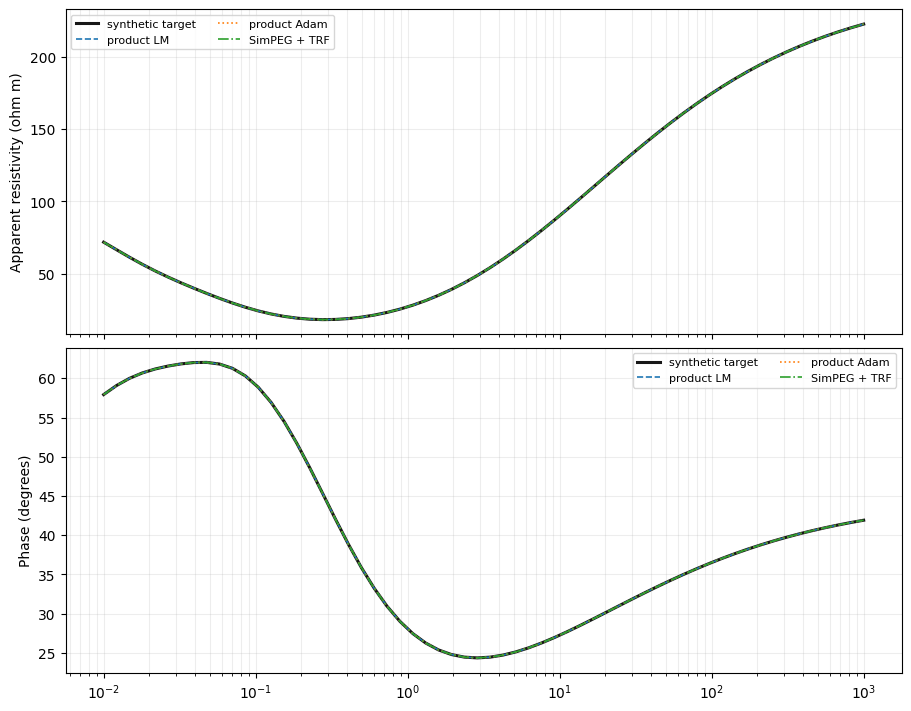

In [12]:
# Split-aware response and normalized complex-residual diagnostic.
z_lm = impedance(fit_lm["model"], h_syn, f_syn)
z_adam = impedance(np.asarray(adam_result["model"]), h_syn, f_syn)
T_syn = 1.0 / f_syn
order = np.argsort(T_syn)
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True, constrained_layout=True)
for component, axis, ylabel in (
    ("apparent", axes[0], "Apparent resistivity (ohm m)"),
    ("phase", axes[1], "Phase (degrees)"),
):
    target = np.asarray(curves(z_syn, f_syn)[component])
    axis.plot(T_syn[order], target[order], color="#171717", lw=2.2, label="synthetic target")
    for label, prediction, style in (
        ("product LM", z_lm, "--"),
        ("product Adam", z_adam, ":"),
        ("SimPEG + TRF", simpeg_prediction, "-."),
    ):
        values = np.asarray(curves(prediction, f_syn)[component])
        axis.plot(T_syn[order], values[order], linestyle=style, lw=1.2, label=label)
    axis.set_xscale("log")
    axis.set_ylabel(ylabel)
    axis.grid(True, which="both", alpha=0.22)
    axis.legend(ncol=2, fontsize=8)
plt.show()


Los paneles comparan resistividad aparente y fase de la misma impedancia sintética para LM, Adam y el ajuste independiente basado en SimPEG. Las frecuencias retenidas se excluyen de la optimización; la concordancia no demuestra unicidad geológica.
 La máscara de frecuencia permanece fija.

Grafique por separado residuos complejos normalizados de frecuencias ajustadas y retenidas; así se conserva la partición que compara el optimizador. La referencia de una sigma muestra la escala, pero los residuos no son muestras independientes de profundidad.


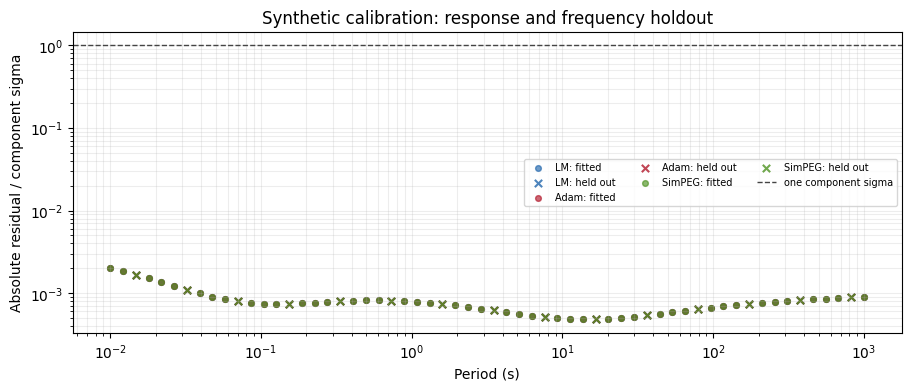

In [13]:
# Compare normalized residuals on fitted and held-out frequencies.
fig, ax = plt.subplots(figsize=(9, 3.8), constrained_layout=True)
for label, prediction, color in (
    ("LM", z_lm, "#2166ac"),
    ("Adam", z_adam, "#b2182b"),
    ("SimPEG", simpeg_prediction, "#4d9221"),
):
    normalized = np.maximum(np.abs(prediction - z_syn) / sigma_syn, 1e-12)
    ax.scatter(T_syn[active_syn], normalized[active_syn], s=17, alpha=0.65, label=f"{label}: fitted", color=color)
    ax.scatter(
        T_syn[~active_syn], normalized[~active_syn], s=28,
        marker="x", alpha=0.8, label=f"{label}: held out", color=color,
    )
ax.axhline(1.0, color="#444444", linestyle="--", linewidth=1, label="one component sigma")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Period (s)")
ax.set_ylabel("Absolute residual / component sigma")
ax.grid(True, which="both", alpha=0.22)
ax.legend(ncol=3, fontsize=7)
ax.set_title("Synthetic calibration: response and frequency holdout")
plt.show()


Estos tres paneles cuantifican sensibilidad local en la referencia sintética: los valores singulares revelan direcciones débiles por ventana, las desviaciones condicionales resumen incertidumbre linealizada y el panel derecho muestra el intercambio espesor/resistividad blanqueado. Son diagnósticos locales, no intervalos de confianza de terreno.

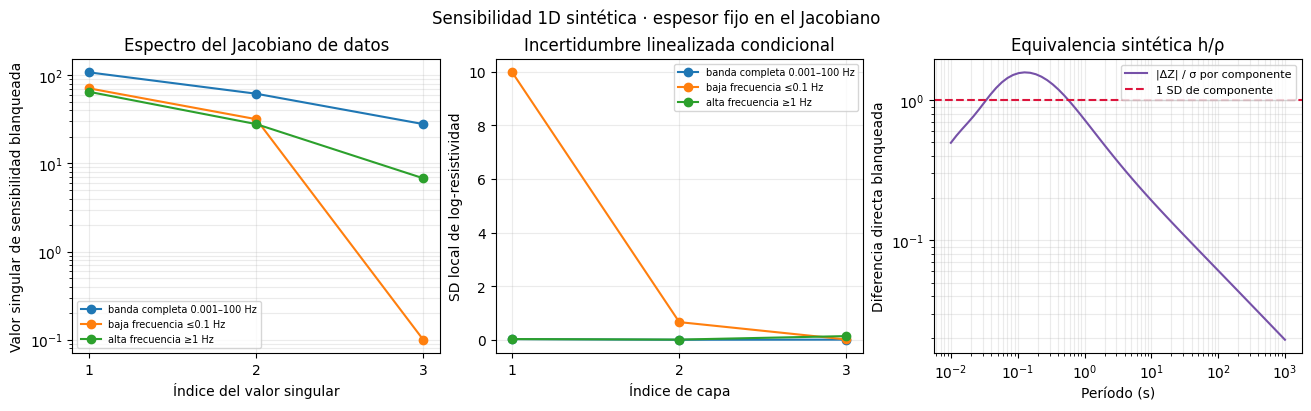

In [14]:
# Ejecute el experimento documentado con la evidencia del repositorio.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for label, d in diags.items():
    s = np.asarray(d["singular_values"], float)
    ax[0].semilogy(np.arange(1, len(s) + 1), s, marker="o", label=label)
    ax[1].plot(np.arange(1, len(rho_syn) + 1), d["local_logrho_sd"], marker="o", label=label)
ax[0].set_xlabel("Índice del valor singular")
ax[0].set_ylabel("Valor singular de sensibilidad blanqueada")
ax[0].set_title("Espectro del Jacobiano de datos")
ax[1].set_xlabel("Índice de capa")
ax[1].set_ylabel("SD local de log-resistividad")
ax[1].set_title("Incertidumbre linealizada condicional")
for a in ax[:2]:
    a.set_xticks(np.arange(1, 4))
    a.grid(True, which="both", alpha=0.25)
    a.legend(fontsize=7)
T = 1 / f_syn
ax[2].loglog(T, whitened, label="|ΔZ| / σ por componente", color="#7651a8")
ax[2].axhline(1, color="crimson", ls="--", label="1 SD de componente")
ax[2].set_xlabel("Período (s)")
ax[2].set_ylabel("Diferencia directa blanqueada")
ax[2].set_title("Equivalencia sintética h/ρ")
ax[2].grid(True, which="both", alpha=0.25)
ax[2].legend(fontsize=8)
fig.suptitle("Sensibilidad 1D sintética · espesor fijo en el Jacobiano")
plt.show()


### Procedencia de datos

Clear Lake cl061 tiene 42 períodos medidos y falla el filtro tensorial 1D necesario; se conserva solo para QC. La comparación de optimizadores usa impedancias sintéticas con semilla y verdad de capas conocida. No se mezclan valores EDI medidos en ese experimento.


## Resultados

El Jacobiano de bajas frecuencias tiene rango 2/3 y SD local de log-resistividad 9.974 en la capa superior; las bandas completa y alta tienen rango 3/3. LM, Adam y el ajuste basado en SimPEG recuperan aproximadamente [79.987, 12.001, 249.984] Ω·m. Todos obtienen WRMS activo por componente de 0.000616; SimPEG obtiene WRMS retenido de 0.000596. La respuesta directa de SimPEG en la verdad sintetica difiere de la del producto como maximo 1.017e-10 en terminos relativos.
### Entradas congeladas del optimizador



**Respuesta:** El Jacobiano de bajas frecuencias tiene rango 2/3 y SD local de log-resistividad 9.974 en la capa superior; las bandas completa y alta tienen rango 3/3. LM, Adam y el ajuste basado en SimPEG recuperan aproximadamente [79.987, 12.001, 249.984] Ω·m. Todos obtienen WRMS activo por componente de 0.000616; SimPEG obtiene WRMS retenido de 0.000596. La respuesta directa de SimPEG en la verdad sintetica difiere de la del producto como maximo 1.017e-10 en terminos relativos.

LM y Adam comparten vector de impedancia y reserva sintéticos; el barrido de identificabilidad solo cambia la banda de frecuencias.

La concordancia del ajuste SimPEG depende de convenciones de signo y orden explicitamente adaptadas y verificadas. El motor directo es independiente; el optimizador TRF y el objetivo son compartidos.


## Resumen

El subconjunto de baja frecuencia deja una capa localmente no resuelta aunque la banda completa no. El acuerdo LM/Adam valida dos implementaciones sobre este objetivo sintético; no establece unicidad global, ruido realista, dimensionalidad ni transferencia a terreno.

La comprobacion SimPEG verifica el motor directo y la convencion con los datos sinteticos; no constituye un algoritmo nuevo, inversion de campo ni prueba de unicidad geologica.


### Usalo con tus propios datos

Para cada frecuencia el dato es la impedancia compleja Z. El experimento asigna una desviacion estandar de 3 % a cada componente real; es una escala sintetica, no una covarianza EDI. Con A como frecuencias activas y NL capas, el objetivo es

$$r_j=(Z_j^{pred}-Z_j^{obs})/sigma_j,\qquad Z_N(omega)=sqrt(i omega mu_0 rho_N).$$

$$J=(1/(2 N_A)) sum_{j in A}[(Re r_j)^2+(Im r_j)^2]+beta/(N_L-1) sum_k(Delta log rho_k)^2,\quad beta=10^{-3}.$$

La figura presenta resistividad aparente y fase; abajo muestra el residual complejo absoluto dividido por sigma de componente. Las frecuencias retenidas no entran en el objetivo ni en la seleccion de parametros. Como ajustadas y retenidas provienen de la misma respuesta sintetica exacta, esto solo comprueba el efecto de la mascara; no es validacion geologica independiente. Un residual menor que una sigma compara escalas y no es probabilidad ni intervalo de confianza. El residual pequeno no nulo aparece en parte porque la regularizacion separa la solucion del modelo exacto. Registre frecuencia, mascara, incertidumbre, espesores fijos, inicio, cotas, beta, tolerancias y versiones para reproducir el resultado.

La recursion 1D supone capas horizontales isotropas, fuente de onda plana, respuesta cuasiestatica, interfaces fijas y resistividad escalar. Excluye topografia, anisotropia, distorsion galvanica, static shift, induccion 2D/3D, fuentes cercanas, ruido correlacionado y orientacion incierta. El Jacobiano local depende de espesores fijos y de un entorno del inicio de tres capas. Su rango no enumera alternativas no lineales ni prueba unicidad. La perturbacion de conductancia solo es directa, no es un modelo recuperado. cl061 permanece para QC porque falla elegibilidad 1D; no se afirma una inversion de campo.

Para datos propios conserve el EDI con licencia sin modificar, checksum, ID de estacion, coordenadas, unidades, historial y atribucion. Use un parser compatible y verifique azimuts, rotacion, orden de frecuencia, unidades y fase. Inspeccione errores, coherencia, tensor, determinante, tensor de fase y tipper antes de seleccionar un modo 1D. Separe QC de la mascara de ajuste. Declare el observable usado y derive incertidumbre/covarianza desde la adquisicion. Antes de mirar el resultado defina capas, espesores libres o fijos, cotas, inicio, regularizacion, parada y mascara. Use varios inicios, inspecte residuales estandarizados reales e imaginarios y reserve frecuencias o estaciones para una comprobacion descrita. Si fija espesores, declare que la resistividad depende de esas profundidades. Cuando QC o dimensionalidad contradigan 1D, cambie la clase del modelo en vez de forzar la inversion. Guarde derivados con procedencia; no reemplace silenciosamente las observaciones fuente. La receta publicada de SimPEG ofrece otra ruta practica: permite invertir resistividad aparente y fase con un mapa de conductividad estratificado, regularizacion de suavidad, programacion de beta, misfit objetivo e historial de iteraciones. Su parametrizacion y ponderacion de incertidumbre pueden diferir de este experimento de tres capas fijas e impedancia compleja. Una comparacion responsable debe declarar si coinciden tipo de dato, ruido, geometria y objetivo; no debe llamar equivalentes a dos curvas solo porque ambas se etiqueten MT 1D.


### ### Estado del optimizador y alcance de la paridad

El metodo LM del producto usa minimos cuadrados acotados de region de confianza; Adam es un optimizador de primer orden de Torch. Ambos reciben el mismo vector de frecuencias, objetivo complejo, escala por componente, mascara activa, resistividad inicial y geometria fija. Sus trayectorias y criterios de parada difieren; por ello coincidir en modelo final y residual es una comprobacion numerica util para este objetivo. El calculo SimPEG cambia la implementacion electromagnetica recursiva y el adaptador de coordenadas/signo, pero mantiene SciPy TRF y el objetivo. La asercion de paridad directa se verifica en el modelo sintetico conocido antes de invertir; despues, el ajuste estima parametros sin recibir esa verdad. El residual retenido se calcula al converger. Estas comprobaciones detectan errores de convencion como capas invertidas, signo, cuadrante de fase, orden de frecuencia e intercalado real/imaginario. No demuestran que los supuestos compartidos sean correctos ni que los metodos transfieran a datos ruidosos y multidimensionales. Una comparacion futura de campo debe usar el mismo modo derivado del EDI y su covarianza, documentar todo procesamiento y conservar una estacion o adquisicion independiente para evaluacion.


## Referencias

- [https://github.com/MTgeophysics/mtpy-v2](https://github.com/MTgeophysics/mtpy-v2)
- [https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california)
- SimPEG 2017 1D MT tutorial: https://storage.googleapis.com/simpeg/papers/2017/tle36080696.1.pdf
- SimPEG 0.25.2 recursive 1D API: https://docs.simpeg.xyz/v0.25.2/content/api/generated/simpeg.electromagnetics.natural_source.simulation_1d.Simulation1DRecursive.html
